<a href="https://colab.research.google.com/github/eloiisehenry/tp3_nlp/blob/main/TP3_EloiseHENRY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 2.3 – Analyse Prédictive par NLP : Classification de Sentiments sur des Tweets

## 1. Contexte, Justification et Objectifs du Cas d'Usage

### Choix du cas d'usage
Le cas d'usage retenu consiste à classifier automatiquement la polarité des sentiments de tweets (positif, négatif, neutre ou non pertinent). Ce choix s'explique par la nécessité pour les entreprises d'automatiser le suivi de la satisfaction client et de la réputation de leurs marques en temps réel, face au volume massif de données textuelles générées sur les réseaux sociaux.

### Objectifs de la démarche
Ce projet met en œuvre un pipeline complet de traitement du langage naturel (NLP) et de classification supervisée :
- **Prétraitement et vectorisation** : transformation des textes bruts en représentations numériques exploitables via la méthode TF-IDF.
- **Modélisation** : implémentation d'un classificateur de référence (Naive Bayes) et d'un second modèle de machine learning (SVM) pour comparer leurs performances.
- **Évaluation et interprétation** : mesure rigoureuse des résultats à l'aide d'ensembles d'entraînement et de validation distincts, suivie d'une analyse critique des prédictions.

###Etape 1 : Prétraitement et nettoyage des données (Text Cleaning & Normalization)


In [ ]:
# Chargement des fichiers CSV d'entraînement et de validation.
import pandas as pd
import numpy as np

#Données brutes
train_df = pd.read_csv('twitter_training.csv', header=None)
val_df = pd.read_csv('twitter_validation.csv', header=None)

# Initialement le dataset n'a pas d'en-tête, on a donc nommé explicitement les colonnes.
train_df.columns = ['ID', 'Topic', 'Sentiment', 'Text']
val_df.columns = ['ID', 'Topic', 'Sentiment', 'Text']

# Nettoyage des données : on supprime les valeurs manquantes (NaN) dans les textes pour éviter des erreurs pour l'étape de vectorisation.
train_df = train_df.dropna(subset=['Text'])
val_df = val_df.dropna(subset=['Text'])

#Affichage des 10 premiere ligne pour avoir une vue sur le dataset
print(train_df.head(10))

     ID        Topic Sentiment  \
0  2401  Borderlands  Positive   
1  2401  Borderlands  Positive   
2  2401  Borderlands  Positive   
3  2401  Borderlands  Positive   
4  2401  Borderlands  Positive   
5  2401  Borderlands  Positive   
6  2402  Borderlands  Positive   
7  2402  Borderlands  Positive   
8  2402  Borderlands  Positive   
9  2402  Borderlands  Positive   

                                                Text  
0  im getting on borderlands and i will murder yo...  
1  I am coming to the borders and I will kill you...  
2  im getting on borderlands and i will kill you ...  
3  im coming on borderlands and i will murder you...  
4  im getting on borderlands 2 and i will murder ...  
5  im getting into borderlands and i can murder y...  
6  So I spent a few hours making something for fu...  
7  So I spent a couple of hours doing something f...  
8  So I spent a few hours doing something for fun...  
9  So I spent a few hours making something for fu...  


###Etape 2 : Vectorisation (Conversion du texte en matrice)

Pour la vectorisation, la méthode TF-IDF est utilisée car elle va ponderer l'importance des termes en réduisant le poids des mots trop fréquents et en valorisant aussi les mots spécifiques porteurs d'un sens fort pour la classification.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# On sélectionne les 2500 mots les plus importants du texte pour créer un dictionnaire de référence,
#puis on convertit chaque tweet en une ligne de chiffres basée sur ce dictionnaire.
vectorizer = TfidfVectorizer(max_features=2500, stop_words='english')

# Le modèle apprend le vocabulaire à partir des tweets d'entraînement et les convertit en tableau de nombres.
X_train = vectorizer.fit_transform(train_df['Text'])
y_train = train_df['Sentiment'].values

# On convertit les tweets de validation en utilisant le MÊME dictionnaire de référence créé juste avant.
X_val = vectorizer.transform(val_df['Text'])
y_val = val_df['Sentiment'].values

print("Dimensions de la matrice d'entraînement TF-IDF :", X_train.shape)
print("Dimensions de la matrice de validation TF-IDF :", X_val.shape)

Dimensions de la matrice d'entraînement TF-IDF : (73996, 2500)
Dimensions de la matrice de validation TF-IDF : (1000, 2500)


**Interpretation des résultats :** Les 73 996 tweets d'apprentissage et les 1 000 tweets de test ont été transformés en tableaux de chiffres, en se basant sur une liste commune de 2 500 mots importants.

### Étape 3 : Modélisation

####(Entraînement avec Naive Bayes)

In [ ]:
# On utilise Multinomial Naive Bayes pour classer des textes basés sur des fréquences de mots.
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Entraînement du modèle avec les données transformées
model_nb = MultinomialNB()
model_nb.fit(X_train, y_train)

# Prédiction des sentiments sur le jeu de validation
y_pred_nb = model_nb.predict(X_val)

# Calcul du taux de bonne prédiction (Accuracy)
acc_nb = accuracy_score(y_val, y_pred_nb)
print(f"Précision (Accuracy) de Naive Bayes : {acc_nb * 100:.2f}%")

Précision (Accuracy) de Naive Bayes : 66.20%


**Interpretation des résultats :** Le modèle obtient une précision de **66,20 %**. C'est plutôt pas mal pour une première base, surtout qu'on a 4 choix de sentiments différents (au hasard, on serait à 25 %). Du coup, on peut voir qu'il arrive bien à capter le sens global des tweets, mais il n'est pas à son maximum de ses capacités.

####(Entrainement avec SVM)

In [ ]:
# On utilise l'algorithme LinearSVC, qui est souvent très performant et rapide
# pour classifier des textes représentés par des matrices de mots (TF-IDF).
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

# Entraînement du modèle SVM
model_svm = LinearSVC(random_state=42)
model_svm.fit(X_train, y_train)

# Prédiction sur les données de validation
y_pred_svm = model_svm.predict(X_val)

# Calcul du score de précision
acc_svm = accuracy_score(y_val, y_pred_svm)
print(f"Précision (Accuracy) du modèle SVM : {acc_svm * 100:.2f}%")

Précision (Accuracy) du modèle SVM : 74.30%


**Interprétation des résultats :** Le modèle a été amélioré, on est passé de **66,20 % avec Naive Bayes à 74,30 % avec le SVM**. Le modèle a clairement été amélioré, il fait moins d'erreurs pour deviner les sentiments des tweets.

### Étape 5 : Évaluation

Dans cette partie, on va évaluer en détail les performances du modèle SVM. On va utiliser la matrice de confusion pour voir comment le modèle va classer chaque sentiment et identifier ses points forts ainsi que ses erreurs les plus fréquentes.

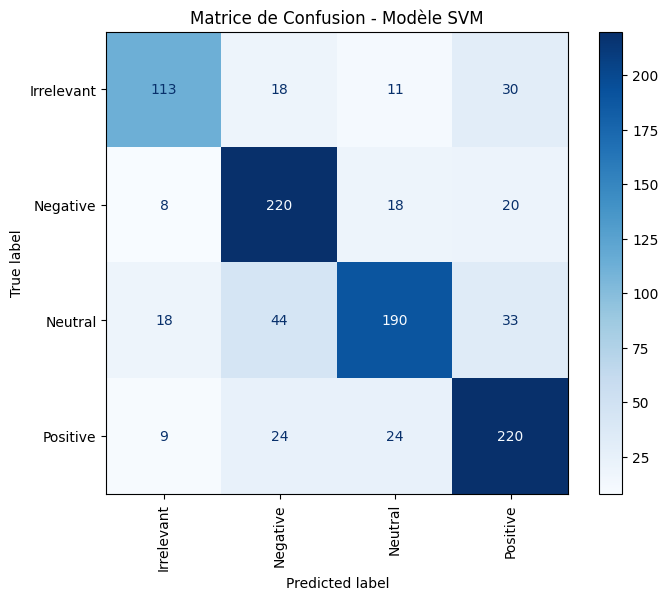


Rapport de classification pour le modèle SVM :

              precision    recall  f1-score   support

  Irrelevant       0.76      0.66      0.71       172
    Negative       0.72      0.83      0.77       266
     Neutral       0.78      0.67      0.72       285
    Positive       0.73      0.79      0.76       277

    accuracy                           0.74      1000
   macro avg       0.75      0.74      0.74      1000
weighted avg       0.75      0.74      0.74      1000



In [ ]:
# On trace la matrice de confusion pour le modèle SVM afin d'analyser en détail les erreurs de prédiction par catégorie de sentiment.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# Calcul de la matrice de confusion avec les classes du modèle SVM
cm = confusion_matrix(y_val, y_pred_svm, labels=model_svm.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model_svm.classes_)

# Affichage du graphique
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title("Matrice de Confusion - Modèle SVM")
plt.show()
print ()
# Affichage du rapport complet pour le modèle SVM
print("Rapport de classification pour le modèle SVM :\n")
print(classification_report(y_val, y_pred_svm))

**Interpretation des résultats :**
- On voit que le  modèle s'en sort très bien pour repérer les tweets négatifs (220 corrects) et positifs (220 corrects), où il fait le moins d'erreurs. Par contre, on voit qu'il hésite un peu plus entre les tweets neutres et les autres catégories, notamment en confondant parfois le neutre avec du négatif (44 erreurs) ou du positif (33 erreurs), ce qui est logique puisque ces nuances sont souvent proches dans les messages.

- En complément de la matrice de confusion, le rapport de classification montre en détail les performances par classe (Precision, Recall et F1-score). On remarque ainsi que les classes extrêmes (positif et négatif) obtiennent les meilleurs scores, tandis que les classes intermédiaires (neutre et non pertinent) demandent plus de subtilité au modèle, confirmant la complexité de l'analyse des sentiments textuels.